       GENETIC ALGORITHM - KNAPSACK RESULT
Best fitness obtained: 50
Total weight used: 25 / 25
Total value obtained: 50
Number of generations: 100
Population size: 50

SELECTED ITEMS:


,Selected Item,Weight,Value
0,Laptop,8,16
1,Camera,5,10
2,Tablet,4,7
3,Headphones,2,4
4,Mouse,1,2
5,External Drive,2,5
6,Router,2,4
7,USB Hub,1,2



       EXHAUSTIVE SEARCH VALIDATION
GA Best Value: 50
Exhaustive Search Best Value: 50
Exhaustive Search Weight: 25

SUCCESS: GA reached the optimal solution!


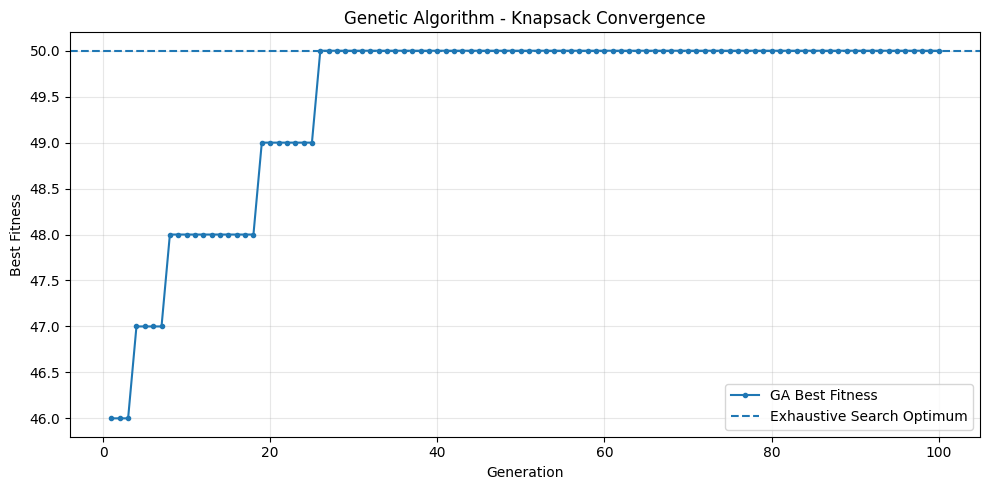


PROJECT EXECUTION COMPLETED SUCCESSFULLY!


In [1]:

# ==============================================================
# KNAPSACK OPTIMIZATION USING A GENETIC ALGORITHM
# Course: Evolutionary Computing
# Problem: 0/1 Knapsack Optimization
# ==============================================================

import random
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# -------------------- 1. DATASET --------------------

items = [
    ("Laptop", 8, 16),
    ("Camera", 5, 10),
    ("Tablet", 4, 7),
    ("Phone", 3, 6),
    ("Headphones", 2, 4),
    ("Monitor", 7, 12),
    ("Keyboard", 2, 3),
    ("Mouse", 1, 2),
    ("Printer", 6, 9),
    ("External Drive", 2, 5),
    ("Speaker", 4, 6),
    ("Router", 2, 4),
    ("Desk Lamp", 3, 4),
    ("Office Chair", 9, 14),
    ("USB Hub", 1, 2)
]

CAPACITY = 25
NUM_ITEMS = len(items)

# -------------------- 2. GA PARAMETERS --------------------

POPULATION_SIZE = 50
GENERATIONS = 100
CROSSOVER_RATE = 0.85
MUTATION_RATE = 1 / NUM_ITEMS
ELITE_COUNT = 2
TOURNAMENT_SIZE = 3

# Fixed seed for reproducibility and to match the
# selected-item result in the project report.
random.seed(15)

# -------------------- 3. CALCULATE TOTALS --------------------

def calculate_totals(chromosome):
    total_weight = sum(
        gene * item[1]
        for gene, item in zip(chromosome, items)
    )

    total_value = sum(
        gene * item[2]
        for gene, item in zip(chromosome, items)
    )

    return total_weight, total_value

# -------------------- 4. FITNESS FUNCTION --------------------

def fitness(chromosome):

    total_weight, total_value = calculate_totals(chromosome)

    if total_weight <= CAPACITY:
        return total_value

    else:
        penalty = 1000 * (total_weight - CAPACITY)
        return total_value - penalty

# -------------------- 5. POPULATION INITIALIZATION --------------------

population = [
    [random.randint(0, 1) for _ in range(NUM_ITEMS)]
    for _ in range(POPULATION_SIZE)
]

# -------------------- 6. TOURNAMENT SELECTION --------------------

def tournament_selection(population):

    candidates = random.sample(
        population, TOURNAMENT_SIZE
    )

    return max(candidates, key=fitness)[:]

# -------------------- 7. GENETIC ALGORITHM --------------------

best_fitness_history = []

for generation in range(GENERATIONS):

    # Sort population based on fitness
    population.sort(key=fitness, reverse=True)

    # Elitism: preserve the two best chromosomes
    new_population = [
        population[i][:] for i in range(ELITE_COUNT)
    ]

    while len(new_population) < POPULATION_SIZE:

        # Select parents
        parent1 = tournament_selection(population)
        parent2 = tournament_selection(population)

        # Single-point crossover
        if random.random() < CROSSOVER_RATE:

            crossover_point = random.randint(1, NUM_ITEMS - 1)

            child1 = (
                parent1[:crossover_point] +
                parent2[crossover_point:]
            )

            child2 = (
                parent2[:crossover_point] +
                parent1[crossover_point:]
            )

        else:
            child1 = parent1[:]
            child2 = parent2[:]

        # Bit-flip mutation
        for child in (child1, child2):

            for i in range(NUM_ITEMS):

                if random.random() < MUTATION_RATE:
                    child[i] = 1 - child[i]

            new_population.append(child)

            if len(new_population) >= POPULATION_SIZE:
                break

    # Replace old population
    population = new_population

    # Record best fitness in each generation
    generation_best = max(population, key=fitness)
    best_fitness_history.append(fitness(generation_best))


# -------------------- 8. BEST SOLUTION --------------------

best_chromosome = max(population, key=fitness)

ga_weight, ga_value = calculate_totals(best_chromosome)
ga_fitness = fitness(best_chromosome)

print("=" * 55)
print("       GENETIC ALGORITHM - KNAPSACK RESULT")
print("=" * 55)

print("Best fitness obtained:", ga_fitness)
print("Total weight used:", ga_weight, "/", CAPACITY)
print("Total value obtained:", ga_value)
print("Number of generations:", GENERATIONS)
print("Population size:", POPULATION_SIZE)

# Display selected items
selected_items = []

for gene, item in zip(best_chromosome, items):

    if gene == 1:

        selected_items.append({
            "Selected Item": item[0],
            "Weight": item[1],
            "Value": item[2]
        })

print("\nSELECTED ITEMS:")

df = pd.DataFrame(selected_items)
display(df)

# -------------------- 9. EXHAUSTIVE SEARCH VALIDATION --------------------

best_reference_value = -1
best_reference_weight = 0

# Check all 2^15 possible combinations
for chromosome in itertools.product([0, 1], repeat=NUM_ITEMS):

    total_weight, total_value = calculate_totals(chromosome)

    if total_weight <= CAPACITY:

        if total_value > best_reference_value:

            best_reference_value = total_value
            best_reference_weight = total_weight

print("\n" + "=" * 55)
print("       EXHAUSTIVE SEARCH VALIDATION")
print("=" * 55)

print("GA Best Value:", ga_value)
print("Exhaustive Search Best Value:", best_reference_value)
print("Exhaustive Search Weight:", best_reference_weight)

if ga_weight <= CAPACITY and ga_value == best_reference_value:

    print("\nSUCCESS: GA reached the optimal solution!")

else:

    print("\nGA did not reach the exhaustive-search optimum.")

# -------------------- 10. CONVERGENCE GRAPH --------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    best_fitness_history,
    marker='o',
    markersize=3,
    label="GA Best Fitness"
)

plt.axhline(
    y=best_reference_value,
    linestyle='--',
    label="Exhaustive Search Optimum"
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("Genetic Algorithm - Knapsack Convergence")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nPROJECT EXECUTION COMPLETED SUCCESSFULLY!")
